# Question 7: Multinomial Logistic Regression Decision Boundary

## Cell 1: Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder

## Cell 2: Load Dataset

In [2]:
# Load iris dataset (handles Iris.csv or iris.csv)
filename = "Iris.csv" if os.path.exists("Iris.csv") else "iris.csv"
df = pd.read_csv(filename)
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## Cell 3: Inspect Dataset Columns

In [3]:
print("Columns in dataset:", list(df.columns))

Columns in dataset: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


## Cell 4: Select Features and Encode Target

In [4]:
# Identify column names for petal length, petal width, and species
col_petal_len = [c for c in df.columns if "petal" in c.lower() and "length" in c.lower()][0]
col_petal_wid = [c for c in df.columns if "petal" in c.lower() and "width" in c.lower()][0]
col_species   = [c for c in df.columns if "species" in c.lower() or "target" in c.lower() or "class" in c.lower()][0]

# Select only petal length and petal width as features
X = df[[col_petal_len, col_petal_wid]].values

# Encode species labels into numerical classes
le = LabelEncoder()
y = le.fit_transform(df[col_species])
species_names = le.classes_

print(f"Selected features: {col_petal_len}, {col_petal_wid}")
print(f"Target classes ({len(species_names)}): {list(species_names)}")

Selected features: PetalLengthCm, PetalWidthCm
Target classes (3): ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']


## Cell 5: Train Logistic Regression Model

In [5]:
# Fit 3-class multinomial logistic regression model
try:
    model = LogisticRegression(multi_class="multinomial", solver="lbfgs", max_iter=1000)
except TypeError:
    model = LogisticRegression(solver="lbfgs", max_iter=1000)

model.fit(X, y)
print("Model training complete.")

Model training complete.


## Cell 6: Generate Mesh Grid and Predict Classes

In [6]:
# Define bounds with margin
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

# Create mesh grid covering feature ranges
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Predict the class for each point on the grid
grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = model.predict(grid_points)
Z = Z.reshape(xx.shape)

## Cell 7: Plot Filled Decision Boundary and Training Points

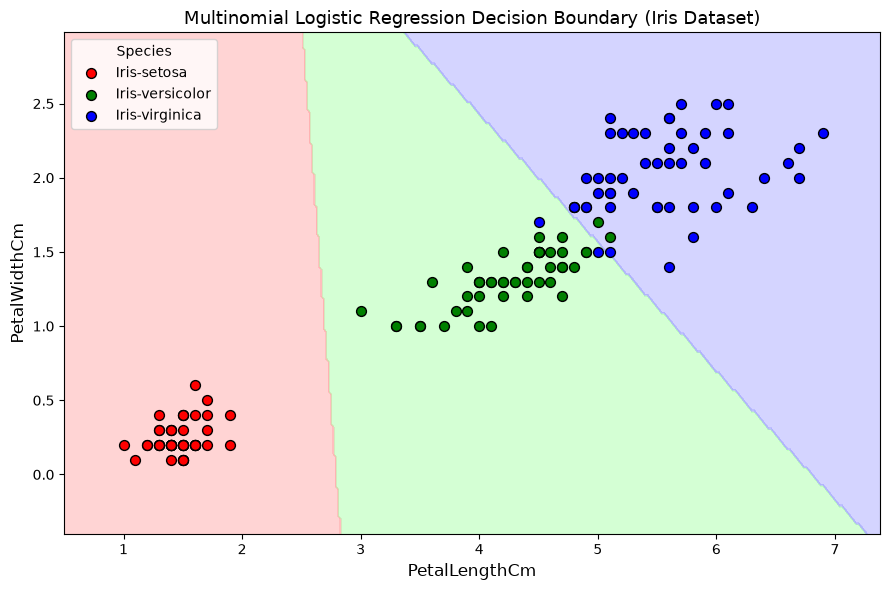

In [7]:
plt.figure(figsize=(9, 6))

# Color maps for decision boundary regions and scatter points
colors = ["#FFAAAA", "#AAFFAA", "#AAAAFF"]
scatter_colors = ["red", "green", "blue"]
cmap_bg = plt.cm.colors.ListedColormap(colors)

# Plot filled decision regions
plt.contourf(xx, yy, Z, alpha=0.5, cmap=cmap_bg)

# Overlay original training points with different colors
for i, name in enumerate(species_names):
    plt.scatter(
        X[y == i, 0],
        X[y == i, 1],
        color=scatter_colors[i],
        edgecolor="k",
        label=name,
        s=50
    )

plt.xlabel(col_petal_len, fontsize=12)
plt.ylabel(col_petal_wid, fontsize=12)
plt.title("Multinomial Logistic Regression Decision Boundary (Iris Dataset)", fontsize=13)
plt.legend(title="Species", loc="upper left")
plt.tight_layout()
plt.show()

## Cell 8: Conclusion

### Decision Boundary Analysis:
1. **Linear Boundaries:** Multinomial Logistic Regression creates linear decision boundaries separating the three Iris species in the 2D feature space.
2. **Iris-setosa:** Clearly linearly separable from the other two species with distinctly smaller petal length (< 2.5 cm) and petal width (< 1.0 cm).
3. **Iris-versicolor vs. Iris-virginica:** Versicolor occupies the intermediate region, while Virginica has larger petal length and petal width. The decision boundary divides the two classes with high separation, reflecting minor overlap near the boundary.